# 01. Обзор данных: вакансии Кыргызстана

**Источник:** открытый датасет School of Data Kyrgyzstan («Кыргызстан в цифрах»),
https://datakyrgyzstan.opendata.kg/vacancy. Вакансии собраны с headhunter.kg и lalafo.kg.

**Цель ноутбука:** понять, что есть в данных, до любой очистки: размер, типы признаков,
период, пропуски, целевая переменная (зарплата).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"

df = pd.read_excel("../data/raw/vacancy.xlsx")
print(df.shape)
df.head(3)

(13349, 22)


,id,name,company,category,sub_category,compensation_from,compensation_to,compensation_currency,requirements,responsibilities,skills,link,experience_start,experience_to,area,address_city,address_street,address_building,address_display_name,publication_time,last_change_time,source
0,94482414,Механик по ремонту и эксплуатации автомобилей,Интерпост,Рабочий персонал,"Автослесарь, автомеханик",40000.0,50000.0,KGS,Требования:Компании требуется механик по ремонту и эксплуатации автомобилей....,Следить за исправностью и эксплуатацией автомобилей.,"Работа в команде, Организаторские навыки, Контроль исправности оборудования,...",https://bishkek.headhunter.kg/vacancy/94482414,3,6.0,Бишкек,Бишкек,"Ленинский район, проспект Чынгыза Айтматова",38,"Бишкек, Ленинский район, проспект Чынгыза Айтматова, 38",1711614926,1711617283,headhunter
1,95570230,Автомеханик,ОсОО Даймлер плюс,Рабочий персонал,"Автослесарь, автомеханик",60000.0,NaN,KGS,Опыт работы на СТО с высокой проходимостью от 1 года. Максимальное усвоение ...,Выполнение работ по развал-схождению колес.,"Техническое обслуживание, Знание устройства автомобиля, Диагностика, Обучени...",https://bishkek.headhunter.kg/vacancy/95570230,1,3.0,Бишкек,Бишкек,улица Лермонтова,117,"Бишкек, улица Лермонтова, 117",1711470574,1711470597,headhunter
2,94678677,Автослесарь / автомеханик,Тревел ленд,Рабочий персонал,"Автослесарь, автомеханик",50000.0,60000.0,KGS,Навыки в обслуживании мототехники приветствуются. Опыт работы в ремонте и об...,"Ремонт и обслуживание автомобилей, преимущественно Японские внедорожники: Па...",Автотранспорт,https://bishkek.headhunter.kg/vacancy/94678677,6,NaN,Бишкек,Бишкек,бульвар Молодой Гвардии,96,"Бишкек, бульвар Молодой Гвардии, 96",1710322405,1710322406,headhunter


## 1. Структура: колонки и типы

In [2]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
})
info

,dtype,non_null,missing_%,unique
id,int64,13349,0.0,13349
name,str,13349,0.0,8374
company,str,4294,67.8,1752
category,str,13349,0.0,27
sub_category,str,13349,0.0,169
compensation_from,float64,6376,52.2,319
compensation_to,float64,1378,89.7,115
compensation_currency,str,7712,42.2,5
requirements,str,12941,3.1,12458
responsibilities,str,3479,73.9,3106


## 2. Период данных

`publication_time` хранится как Unix-время (секунды). Переводим в даты.

In [3]:
df["published"] = pd.to_datetime(df["publication_time"], unit="s")
print("Самая ранняя:", df["published"].min())
print("Самая поздняя:", df["published"].max())
print("Доля за февраль–март 2024:", round((df["published"] >= "2024-02-01").mean(), 3))

df.groupby("source")["published"].agg(["min", "median", "max"])

Самая ранняя: 2017-01-23 05:28:13
Самая поздняя: 2024-03-30 13:38:31
Доля за февраль–март 2024: 0.693


,min,median,max
source,,,
headhunter,2024-02-29 03:22:45,2024-03-20 09:28:31,2024-03-30 13:38:31
lalafo,2017-01-23 05:28:13,2024-02-12 00:34:23,2024-03-29 20:10:33


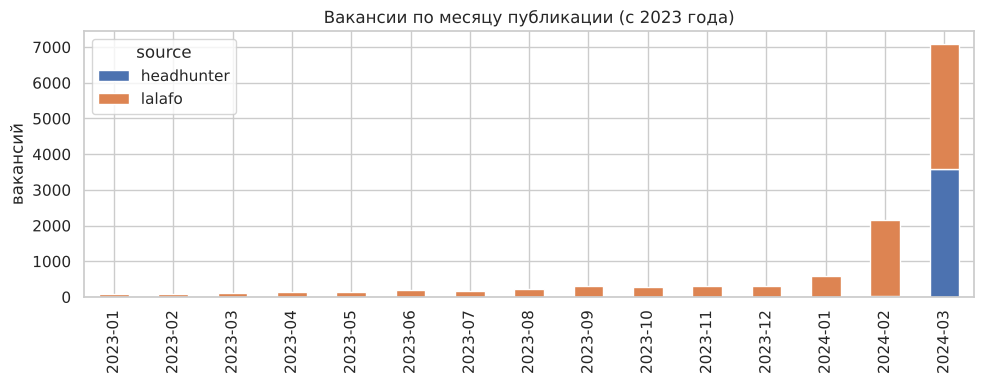

In [4]:
monthly = df[df["published"] >= "2023-01-01"].groupby(
    [df["published"].dt.to_period("M"), "source"]).size().unstack(fill_value=0)
monthly.plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Вакансии по месяцу публикации (с 2023 года)")
plt.xlabel(""); plt.ylabel("вакансий")
plt.tight_layout(); plt.savefig(FIG + "01_months.png", dpi=150); plt.show()

## 3. Источники

In [5]:
df["source"].value_counts()

source
lalafo        9729
headhunter    3620
Name: count, dtype: int64

## 4. Пропуски

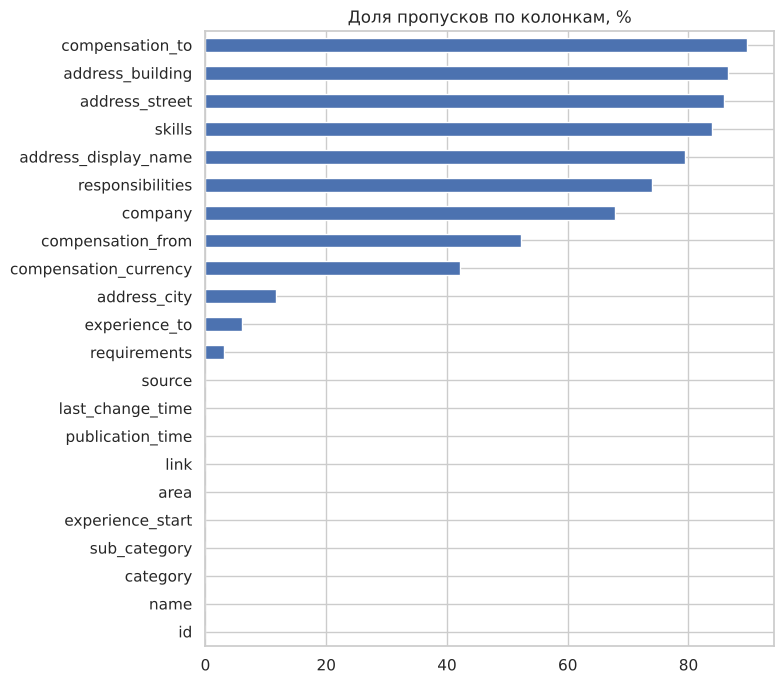

,company,skills,responsibilities,compensation_from
source,,,,
headhunter,0.00,0.4,0.04,0.42
lalafo,0.93,1.0,1.00,0.56


In [6]:
miss = df.drop(columns=["published"]).isna().mean().sort_values() * 100
miss.plot(kind="barh", figsize=(8, 7))
plt.title("Доля пропусков по колонкам, %")
plt.tight_layout(); plt.savefig(FIG + "01_missing.png", dpi=150); plt.show()

# пропуски отдельно по источникам: lalafo и hh заполняют разные поля
df.groupby("source")[["company", "skills", "responsibilities", "compensation_from"]].apply(
    lambda g: g.isna().mean().round(2))

## 5. Целевая переменная: зарплата

Зарплата дана диапазоном `compensation_from` – `compensation_to` и валютой.
Пока только смотрим, без очистки.

In [7]:
has_salary = df["compensation_from"].notna() | df["compensation_to"].notna()
df["has_salary"] = has_salary
print(f"С зарплатой: {has_salary.sum()} из {len(df)} ({has_salary.mean():.0%})")
print(df.groupby("source")["has_salary"].mean().round(2))

df.loc[has_salary, "compensation_currency"].value_counts(dropna=False)

С зарплатой: 6455 из 13349 (48%)
source
headhunter    0.60
lalafo        0.44
Name: has_salary, dtype: float64


compensation_currency
KGS    5956
RUR     250
USD     230
KZT       8
EUR       6
NaN       5
Name: count, dtype: int64

In [8]:
# какая часть границ диапазона заполнена
pd.crosstab(df["compensation_from"].notna(), df["compensation_to"].notna(),
            rownames=["from есть"], colnames=["to есть"])

to есть,False,True
from есть,,
False,6894,79
True,5077,1299


In [9]:
kgs = df[has_salary & (df["compensation_currency"] == "KGS")]
salary_raw = kgs[["compensation_from", "compensation_to"]].mean(axis=1)
print(salary_raw.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))

count    5.956000e+03
mean     5.225620e+05
std      2.056901e+07
min      1.000000e+00
1%       3.000000e+01
5%       7.000000e+02
25%      1.075000e+04
50%      3.000000e+04
75%      5.000000e+04
95%      1.000000e+05
99%      1.506750e+05
max      1.000000e+09
dtype: float64


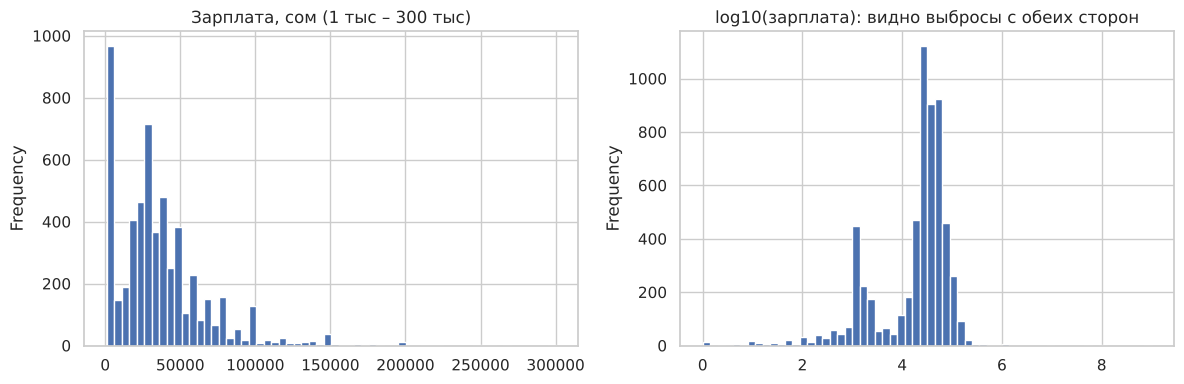

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
salary_raw[salary_raw.between(1_000, 300_000)].plot(kind="hist", bins=60, ax=ax[0])
ax[0].set_title("Зарплата, сом (1 тыс – 300 тыс)")
np.log10(salary_raw[salary_raw > 0]).plot(kind="hist", bins=60, ax=ax[1])
ax[1].set_title("log10(зарплата): видно выбросы с обеих сторон")
plt.tight_layout(); plt.savefig(FIG + "01_salary_raw.png", dpi=150); plt.show()

## 6. Основные признаки

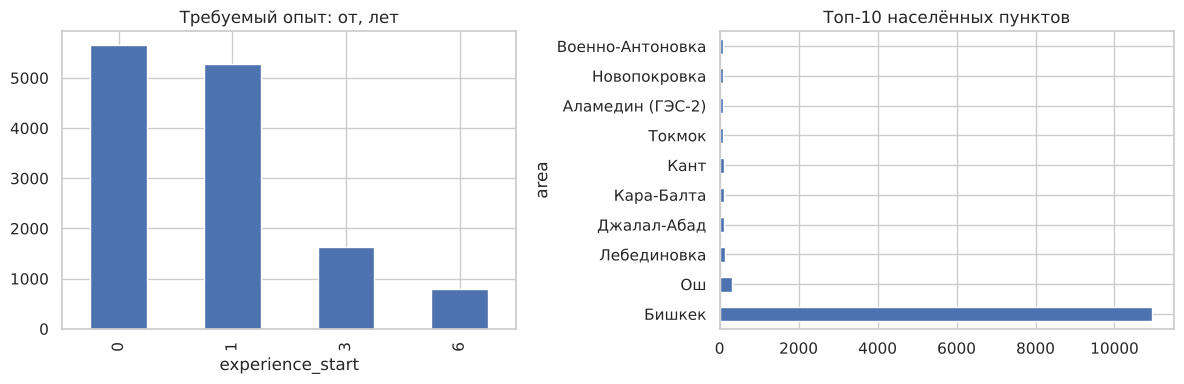

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["experience_start"].value_counts().sort_index().plot(kind="bar", ax=ax[0])
ax[0].set_title("Требуемый опыт: от, лет")
df["area"].value_counts().head(10).plot(kind="barh", ax=ax[1])
ax[1].set_title("Топ-10 населённых пунктов")
plt.tight_layout(); plt.savefig(FIG + "01_experience_area.png", dpi=150); plt.show()

Категорий: 27 | подкатегорий: 169


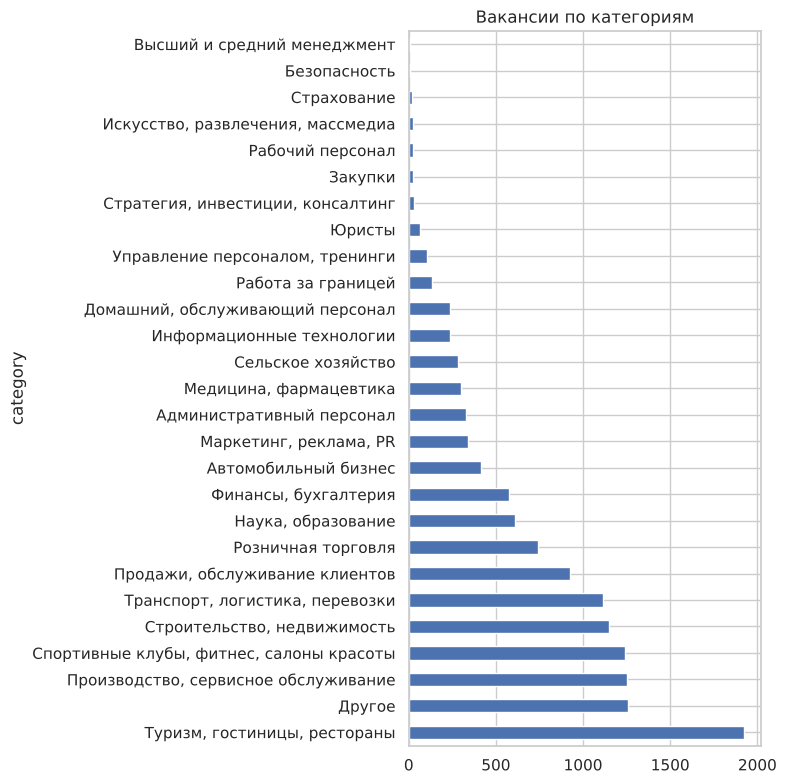

In [12]:
print("Категорий:", df["category"].nunique(), "| подкатегорий:", df["sub_category"].nunique())
df["category"].value_counts().plot(kind="barh", figsize=(8, 8))
plt.title("Вакансии по категориям")
plt.tight_layout(); plt.savefig(FIG + "01_categories.png", dpi=150); plt.show()

In [13]:
skills = df["skills"].dropna().str.split(",").explode().str.strip()
print("Вакансий с навыками:", df["skills"].notna().sum())
skills.value_counts().head(20)

Вакансий с навыками: 2156


skills
Грамотная речь                         292
Активные продажи                       288
Работа в команде                       286
Навыки продаж                          271
Телефонные переговоры                  267
Деловое общение                        254
Пользователь ПК                        219
Деловая переписка                      195
Поиск и привлечение клиентов           189
Деловая коммуникация                   185
Английский язык                        181
Работа с большим объемом информации    167
Обучение и развитие                    160
Заключение договоров                   153
Организаторские навыки                 149
Навыки переговоров                     137
Прямые продажи                         112
Развитие продаж                        102
Грамотность                             95
Ведение переговоров                     86
Name: count, dtype: int64

In [14]:
req = df["requirements"].fillna("").str.lower()
print("Упоминают образование:", round(req.str.contains(r"высше\w* образован|бакалавр|магистр|средне\w* специальн").mean(), 3))
print("Упоминают пол:", round(req.str.contains(r"девушк|парн|мужчин|женщин").mean(), 3))

Упоминают образование: 0.043
Упоминают пол: 0.069


## 7. Дубликаты

In [15]:
print("Повторы id:", df["id"].duplicated().sum())
print("Повторы name + company + зарплата:",
      df.duplicated(["name", "company", "compensation_from"]).sum())

Повторы id: 0
Повторы name + company + зарплата: 2340


## Выводы обзора

> Перепишите своими словами после запуска: на защите спросят именно это.

- **Размер:** ~13,3 тыс. вакансий, 22 колонки; lalafo ≈ 73%, headhunter ≈ 27%.
- **Период:** фактически снимок рынка **февраля–марта 2024** (≈69% публикаций); у lalafo есть
  старые объявления (с 2017), которые ещё висели на сайте.
- **Зарплата указана в ~48% вакансий** → остальные 52% «по договорённости»: их предскажет модель.
- **Валюты:** в основном KGS, есть RUR и USD → привести к сомам.
- **Выбросы:** зарплаты от 1 до 10⁹ сом → нужна очистка (почасовая оплата, опечатки, «тыс»).
- **Опыт** уже структурирован (0 / 1 / 3 / 6 лет) → готовый признак.
- **Навыки** есть почти только у hh; **образование** упоминается лишь в ~4% требований → слабый признак,
  вопрос «влияет ли образование» лучше дополнить официальной статистикой.
- **Пол** упоминается в ~7% объявлений (чаще на lalafo) → возможный интересный инсайт.
- **Дубликаты:** id уникальны, но ~2,3 тыс. совпадений по названию + компании + зарплате → проверить.

**Задача для ML:** регрессия, предсказываем месячную зарплату в сомах по категории, подкатегории,
опыту, городу, источнику и тексту требований.

**Следующий ноутбук:** `02_cleaning.ipynb`.